In [1]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_curve
)

import joblib

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load Adult Income Dataset

adult = fetch_openml(
    name="adult",
    version=2,
    as_frame=True
)

X = adult.data.copy()
y = adult.target.copy()

# Handle missing categorical values

for col in X.select_dtypes(
    include=["object", "category"]
).columns:

    X[col] = X[col].astype("object").replace("?", np.nan)

# Clean target values

y = y.astype(str).str.strip()
y = y.str.replace(r"\.$", "", regex=True)

# Convert target into binary values
# 0 = Income <= 50K
# 1 = Income > 50K

y = y.map({
    "<=50K": 0,
    ">50K": 1
})

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)

display(X.head())

print("\nTarget distribution:")
print(y.value_counts())


Dataset loaded successfully!
Dataset shape: (48842, 14)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States



Target distribution:
class
0    37155
1    11687
Name: count, dtype: int64


In [3]:

# Train and test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Train/Test split completed!")


Training samples: 39073
Testing samples: 9769
Train/Test split completed!


In [4]:

# Identify numerical and categorical features

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numerical preprocessing

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [5]:

# Define four classification models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        random_state=42
    )
}

print("Four machine learning models defined:")
for name in models:
    print("-", name)


Four machine learning models defined:
- Logistic Regression
- Random Forest
- Extra Trees
- Gradient Boosting


In [6]:

# Define hyperparameter grids

param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1.0]
    },

    "Random Forest": {
        "model__max_depth": [None, 20],
        "model__min_samples_leaf": [1, 2]
    },

    "Extra Trees": {
        "model__max_depth": [None, 20],
        "model__min_samples_leaf": [1, 2]
    },

    "Gradient Boosting": {
        "model__learning_rate": [0.05, 0.1],
        "model__max_leaf_nodes": [15, 31]
    }
}

print("Hyperparameter grids created successfully!")


Hyperparameter grids created successfully!


In [7]:

# Stratified K-Fold Cross Validation

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

best_models = {}
comparison_results = []

# Tune each model

for name, model in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_

    print("Best Parameters:", grid_search.best_params_)
    print("Best CV ROC-AUC:", round(
        grid_search.best_score_, 4
    ))

    comparison_results.append({
        "Model": name,
        "Best CV ROC-AUC": grid_search.best_score_,
        "Best Parameters": str(grid_search.best_params_)
    })

print("\nAll four models tuned successfully!")



Training: Logistic Regression
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best Parameters: {'model__C': 1.0}
Best CV ROC-AUC: 0.9055

Training: Random Forest
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2}
Best CV ROC-AUC: 0.9144

Training: Extra Trees
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2}
Best CV ROC-AUC: 0.8984

Training: Gradient Boosting
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 31}
Best CV ROC-AUC: 0.9262

All four models tuned successfully!


In [8]:

# Evaluate all tuned models

evaluation_results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    evaluation_results.append({
        "Model": name,
        "CV ROC-AUC": next(
            r["Best CV ROC-AUC"]
            for r in comparison_results
            if r["Model"] == name
        ),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(evaluation_results)

print("MODEL COMPARISON TABLE")

display(
    results_df.sort_values(
        by="CV ROC-AUC",
        ascending=False
    ).round(4)
)


MODEL COMPARISON TABLE


,Model,CV ROC-AUC,Accuracy,Precision,Recall,F1-Score,ROC-AUC
3,Gradient Boosting,0.9262,0.8747,0.7845,0.6570,0.7151,0.9295
1,Random Forest,0.9144,0.8368,0.6202,0.8212,0.7067,0.9167
0,Logistic Regression,0.9055,0.8072,0.5651,0.8443,0.6771,0.9044
2,Extra Trees,0.8984,0.8032,0.5593,0.8370,0.6705,0.8987


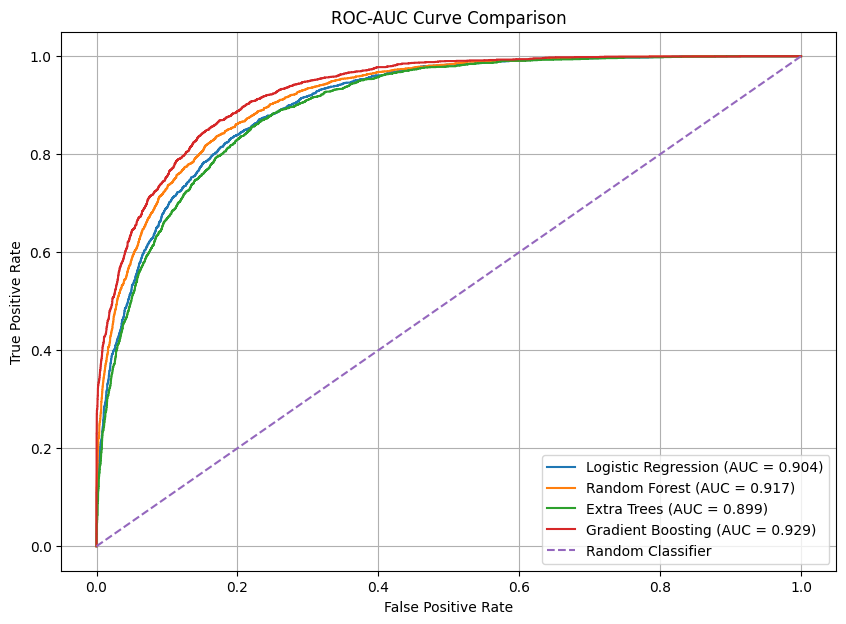

In [9]:

# Plot ROC curves for all models

plt.figure(figsize=(10, 7))

for name, model in best_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC-AUC Curve Comparison")

plt.legend()
plt.grid()
plt.show()


In [10]:

# Select best model using validation performance

champion_row = results_df.loc[
    results_df["CV ROC-AUC"].idxmax()
]

champion_name = champion_row["Model"]

champion_model = best_models[champion_name]

print("CHAMPION MODEL SELECTED")
print("-----------------------")

print("Best Model:", champion_name)

print(
    "Validation ROC-AUC:",
    round(champion_row["CV ROC-AUC"], 4)
)

print("\nChampion model selected successfully!")


CHAMPION MODEL SELECTED
-----------------------
Best Model: Gradient Boosting
Validation ROC-AUC: 0.9262

Champion model selected successfully!


CHAMPION MODEL: Gradient Boosting

Classification Report:
              precision    recall  f1-score   support

Income <=50K       0.90      0.94      0.92      7431
 Income >50K       0.78      0.66      0.72      2338

    accuracy                           0.87      9769
   macro avg       0.84      0.80      0.82      9769
weighted avg       0.87      0.87      0.87      9769

Champion Test ROC-AUC: 0.9295


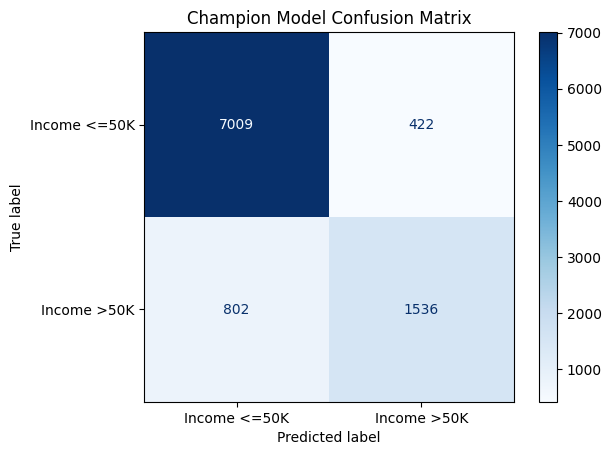

In [11]:

# Evaluate champion model

champion_predictions = champion_model.predict(X_test)

champion_probabilities = (
    champion_model.predict_proba(X_test)[:, 1]
)

print("CHAMPION MODEL:", champion_name)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        champion_predictions,
        target_names=["Income <=50K", "Income >50K"]
    )
)

print(
    "Champion Test ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            champion_probabilities
        ),
        4
    )
)

# Confusion Matrix

cm = confusion_matrix(
    y_test,
    champion_predictions
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Income <=50K", "Income >50K"]
)

display_cm.plot(cmap="Blues")

plt.title("Champion Model Confusion Matrix")
plt.show()


In [12]:

# Save champion model

joblib.dump(
    champion_model,
    "champion_model.joblib"
)

print("Champion model saved successfully!")

# Load saved model

loaded_model = joblib.load(
    "champion_model.joblib"
)

# Test saved model

sample_predictions = loaded_model.predict(
    X_test.head(5)
)

print("\nSample Predictions:")
print(sample_predictions)


Champion model saved successfully!

Sample Predictions:
[0 0 1 0 1]


In [13]:

# Save model comparison table

results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison table saved!")

# Display final results

print("\nFINAL PROJECT SUMMARY")
print("=====================")

print("Models Trained: 4")

print("Models:")
for name in best_models:
    print("-", name)

print("\nChampion Model:", champion_name)

print(
    "Champion Validation ROC-AUC:",
    round(champion_row["CV ROC-AUC"], 4)
)

print("\nPROJECT COMPLETED SUCCESSFULLY!")


Model comparison table saved!

FINAL PROJECT SUMMARY
Models Trained: 4
Models:
- Logistic Regression
- Random Forest
- Extra Trees
- Gradient Boosting

Champion Model: Gradient Boosting
Champion Validation ROC-AUC: 0.9262

PROJECT COMPLETED SUCCESSFULLY!


In [14]:

from google.colab import files

files.download("champion_model.joblib")
files.download("model_comparison_results.csv")

print("Project files downloaded successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Project files downloaded successfully!
